# 10 · Análisis exploratorio: ¿de dónde viene la mejora de `ACP`?

**Etapa 13 del plan.** `ACP` fue la primera configuración que cumplió el criterio de lectura, pero su bloque mezcla el puntaje del mes con su pasado, y usa una sola partición de pliegues. Este notebook separa las dos cosas:
1. **`ACP0`:** `ACH` + solo el puntaje del mes. Mide lo que aporta apilar modelos.
2. **`ACPH`:** `ACH` + solo el puntaje de t−1, t−2 y t−3. Mide lo que aporta la historia.
3. **`ACP_B` y `ACP_C`:** `ACP` completo con otras dos particiones.

**Todo lo de este notebook es exploratorio.** 201909 y 201910 ya se miraron, así que nada de acá demuestra la hipótesis ni cambia el resultado de la regla pre-registrada. Las configuraciones y las lecturas posibles se fijaron en la ficha, antes de correrlo.

**No escribe en `exp/03/` a `exp/09/` ni en los `resultados/03_*` a `09_*`:** solo los lee. **No usa la clase de 201911 ni de 201912.**

Ficha: `fichas/etapa_13_puntaje_por_partes.md` (en el laboratorio).

## 1. Parámetros

**Retomar:** si la corrida se corta, se vuelve a correr entera. Los puntajes y las semillas ya hechas no se repiten.

In [1]:
from pathlib import Path
import gc
import hashlib
import json
import resource
import sys
import time
import warnings

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn.metrics import roc_auc_score

# --- Parámetros -------------------------------------------------------------
BASE_PARQUET = Path('../data/base_2019.parquet')
RESULTADOS = Path('../resultados')
EXP_03 = Path('../exp/03')                          # solo se lee
EXP_06 = Path('../exp/06')                          # solo se lee
EXP_08 = Path('../exp/08')                          # solo se lee
EXP_09 = Path('../exp/09')                          # solo se lee
EXP = Path('../exp/10')
FIGURAS = RESULTADOS / 'figuras'

CONTROL = 'AC'
BASE_CURADA = 'ACH'
NUEVAS = {'ACH': {'lags': [], 'tendencia': None, 'curada': True}}   # la tabla de la que parten todas
COMPLETA = 'ACP'
TODAS_PT = ['pt_0', 'pt_1', 'pt_2', 'pt_3', 'pt_d1', 'pt_d3']
VARIANTES = {                                       # configuración: partición y columnas del bloque de puntaje
    'ACP0': {'particion': 'A', 'columnas': ['pt_0']},
    'ACPH': {'particion': 'A', 'columnas': ['pt_1', 'pt_2', 'pt_3']},
    'ACP_B': {'particion': 'B', 'columnas': TODAS_PT},
    'ACP_C': {'particion': 'C', 'columnas': TODAS_PT},
}
PARTICIONES = {'B': 1, 'C': 2}                      # posición en la lista de semillas; A es la del 09
COMPLETAS = ['ACP', 'ACP_B', 'ACP_C']
CONTRASTES = {'AC': ['ACH', 'ACP'] + list(VARIANTES), 'ACH': ['ACP'] + list(VARIANTES), 'ACP0': ['ACPH']}
N_PLIEGUES = 5

MESES_TRAIN = [201903, 201904, 201905, 201906]
MES_VALID = 201908
MESES_TEST = [201909, 201910]
MESES_EVAL = [MES_VALID] + MESES_TEST
ROTOS_EXTRA = [('ctarjeta_master_descuentos', 201910), ('mtarjeta_master_descuentos', 201910)]

BLOQUE = 20_000                                     # filas por bloque al armar las tablas
N_CURADAS = 30
MINIMO_PREVIOS = 2

SEMILLA_PRIMIGENIA = 979201
N_SEMILLAS = 10
N_BOOTSTRAP = 2_000
NIVEL_IC = 0.95
BANDA = (3_000, 6_000)                              # ambos incluidos
EPSILON = 1e-12
POSITIVOS = ['BAJA+1', 'BAJA+2']
N_HILOS = 8

GANANCIA_ACIERTO = 1_072_500
COSTO_ESTIMULO = 27_500
VENTANA_SUAVIZADO = 501
LARGO_CURVA = 25_000
# -----------------------------------------------------------------------------

PRED = EXP / 'pred'
VARIABLES_CSV = RESULTADOS / '08_variables.csv'     # solo se lee
for d in (PRED, FIGURAS):
    d.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', message='.*ChainedAssignmentError.*')  # falso positivo pandas 2.2 + Py 3.14

ESPERADO_FILAS_POR_MES = {
    201901: 123_916, 201902: 125_020, 201903: 125_622, 201904: 126_116, 201905: 126_763,
    201906: 128_370, 201907: 129_853, 201908: 131_775, 201909: 133_419, 201910: 135_633,
}
ESPERADO_EVAL = {201908: (131_775, 543), 201909: (133_419, 615), 201910: (135_633, 632)}   # filas, BAJA+2
ESPERADO_N_VARIABLES = {'AC': 760, 'ACH': 880}
ESPERADO_ROTOS = 23
VARIABLE_COBERTURA = 'cproductos'


def primos_6_digitos():
    criba = np.ones(1_000_000, dtype=bool)
    criba[:2] = False
    for i in range(2, 1_001):
        if criba[i]:
            criba[i * i::i] = False
    return np.flatnonzero(criba[100_000:]) + 100_000


TODAS = np.random.default_rng(SEMILLA_PRIMIGENIA).choice(primos_6_digitos(), size=20, replace=False).tolist()[:10]
assert TODAS == [294103, 342929, 161093, 677561, 431077, 330679, 511579, 312773, 118147, 567529]
SEMILLAS = TODAS[:N_SEMILLAS]
assert N_SEMILLAS >= 2


def huella_archivos():
    """Control 10: huella de las salidas anteriores, para comprobar que no cambian."""
    return {p.name: hashlib.blake2b(p.read_bytes(), digest_size=16).hexdigest()
            for p in sorted(RESULTADOS.glob('0[3456789]_*'))}


def memoria_gb():
    r = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return round(r / (1e9 if sys.platform == 'darwin' else 1e6), 1)


HUELLA_INICIAL = huella_archivos()
T_INICIO = time.time()
print('Salidas anteriores registradas:', len(HUELLA_INICIAL))

Salidas anteriores registradas: 25


## 2. Dataset y funciones de evaluación

Las mismas funciones del `09`. La clase de 201909 y 201910 solo se usa en la evaluación.

**Control 1:** filas y `BAJA+2` de cada mes.

In [2]:
def curva(prob, es_b2):
    orden = np.argsort(-prob, kind='stable')
    return np.cumsum(np.where(es_b2[orden], GANANCIA_ACIERTO, -COSTO_ESTIMULO))[:LARGO_CURVA].astype(np.float64)


def elegir_n(curva_media):
    suave = pd.Series(curva_media).rolling(VENTANA_SUAVIZADO, center=True, min_periods=VENTANA_SUAVIZADO).mean().to_numpy()
    return int(np.nanargmax(suave)) + 1


def banda(cv):
    return cv[..., BANDA[0] - 1:BANDA[1]].mean(axis=-1)


def wilcoxon_exacto(d):
    d = np.round(np.asarray(d, dtype=np.float64), 6)
    d = d[d != 0]
    n = len(d)
    if n == 0:
        return 1.0
    rangos = stats.rankdata(np.abs(d))
    w = float((np.sign(d) * rangos).sum())
    signos = 1 - 2 * ((np.arange(2 ** n)[:, None] >> np.arange(n)) & 1)
    return float(np.mean(np.abs(signos @ rangos) >= abs(w) - 1e-9))


def ic(x):
    x = np.asarray(x, dtype=np.float64)
    media = x.mean()
    medio = stats.t.ppf((1 + NIVEL_IC) / 2, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return media, media - medio, media + medio


assert abs(wilcoxon_exacto(np.arange(1, 11)) - 2 / 1024) < 1e-12
assert abs(wilcoxon_exacto([1, 1, 1, 1, 1, 1, 1, 1, 1, -1]) - 22 / 1024) < 1e-12

HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())
semillas_06 = pd.read_csv(RESULTADOS / '06_semillas.csv')
HUELLA_AC = json.loads((EXP_06 / 'huellas.json').read_text())[CONTROL]
cobertura = pd.read_csv(RESULTADOS / '01_cobertura_historia.csv', index_col='foto_mes')
claves_npz = np.load(EXP_03 / 'claves_eval.npz')
CLIENTE_EVAL, MES = claves_npz['numero_de_cliente'], claves_npz['foto_mes']

t0 = time.time()
con = duckdb.connect()
base = con.execute(f"""
    select * from read_parquet('{BASE_PARQUET.as_posix()}')
    where foto_mes <= {max(MESES_TEST)}
    order by foto_mes, numero_de_cliente
""").df()
con.close()
assert base['foto_mes'].value_counts().sort_index().to_dict() == ESPERADO_FILAS_POR_MES

CLAVES = ['numero_de_cliente', 'foto_mes', 'clase_ternaria']
VARIABLES = [c for c in base.columns if c not in CLAVES]
BANDERAS = ['active_quarter', 'cliente_vip', 'internet', 'cdescubierto_preacordado',
            'tcallcenter', 'thomebanking', 'tmobile_app', 'ccajas_transacciones']
ESTADOS = ['tcuentas', 'Visa_status', 'Master_status', 'Visa_delinquency', 'Master_delinquency']
FECHAS = [f'{t}_{c}' for t in ('Visa', 'Master') for c in ('Fvencimiento', 'Finiciomora', 'fultimo_cierre', 'fechaalta')]
EDADES = ['cliente_edad', 'cliente_antiguedad']
MONTOS = [v for v in VARIABLES if v not in BANDERAS + ESTADOS + FECHAS + EDADES]
assert len(VARIABLES) == 152 and len(MONTOS) == 129

rotos = pd.read_csv(RESULTADOS / '01_meses_rotos.csv')[['variable', 'foto_mes']]
assert len(rotos) == ESPERADO_ROTOS
rotos = pd.concat([rotos, pd.DataFrame(ROTOS_EXTRA, columns=['variable', 'foto_mes'])], ignore_index=True)
for v, mes in rotos.itertuples(index=False):
    base.loc[base['foto_mes'] == mes, v] = np.nan

FOTO_MES = base['foto_mes'].to_numpy()
PERIODO = (FOTO_MES // 100 * 12 + FOTO_MES % 100).astype(np.int64)
CLAVE = base['numero_de_cliente'].to_numpy(np.int64) * 100_000 + PERIODO
INDICE = pd.Index(CLAVE)
assert INDICE.is_unique
X_MES = np.asfortranarray(base[VARIABLES].to_numpy(np.float32))
CLASE = base['clase_ternaria'].to_numpy()
clase_eval = base.loc[base['foto_mes'].isin(MESES_EVAL), ['numero_de_cliente', 'foto_mes', 'clase_ternaria']]
del base
gc.collect()

eval_ = pd.DataFrame({'numero_de_cliente': CLIENTE_EVAL, 'foto_mes': MES}).merge(
    clase_eval, on=['numero_de_cliente', 'foto_mes'], how='left', validate='one_to_one')
assert eval_['clase_ternaria'].notna().all()
ES_B2 = (eval_['clase_ternaria'] == 'BAJA+2').to_numpy()
es_mes = {m: MES == m for m in MESES_EVAL}
for mes, (filas, b2) in ESPERADO_EVAL.items():            # control 1
    assert (es_mes[mes].sum(), ES_B2[es_mes[mes]].sum()) == (filas, b2), mes
print(f'Dataset cargado en {time.time() - t0:.0f} s · {len(rotos)} casos de meses rotos a NA')

Dataset cargado en 2 s · 25 casos de meses rotos a NA


## 3. Tablas

La misma construcción del `09`.

In [3]:
SIN_HISTORIA = {'lags': [], 'tendencia': None, 'curada': False}
CURADAS = []


def receta(config):
    return SIN_HISTORIA if config == CONTROL else NUEVAS[config]


def especificacion(config):
    ex = receta(config)
    e = [('original', v, 0) for v in VARIABLES]
    e += [(op, v, k) for k in (1, 2) for op in ('lag', 'delta') for v in VARIABLES]
    for k in ex['lags']:
        e += [(op, v, k) for op in ('lag', 'delta') for v in MONTOS + BANDERAS]
        e += [(op, v, k) for op in ('lag', 'cambio') for v in ESTADOS]
    if ex['tendencia']:
        h = ex['tendencia']
        e += [(op, v, h) for op in ('pend', 'prom', 'min', 'max') for v in MONTOS]
        e += [('perm', v, h) for v in BANDERAS]
    if ex['curada']:
        assert len(CURADAS) == N_CURADAS
        e += [(op, v, k) for op, k in (('ratio', 3), ('z', 4), ('relmax', 4), ('mes_ratio', 3)) for v in CURADAS]
    return e


def nombre(op, v, k):
    return v if op == 'original' else f'{v}_{op}{k}'


def construir(config, meses=None):
    ex = receta(config)
    h = ex['tendencia']
    h_max = max([2] + ex['lags'] + [h or 0] + ([4] if ex['curada'] else []))
    filas = np.flatnonzero(np.isin(FOTO_MES, meses or MESES_TRAIN + MESES_EVAL))
    mes_fila = FOTO_MES[filas]
    n_train = int(np.isin(mes_fila, MESES_TRAIN).sum())
    assert meses or (np.isin(mes_fila[:n_train], MESES_TRAIN).all() and np.isin(mes_fila[n_train:], MESES_EVAL).all())
    pos = {k: INDICE.get_indexer(CLAVE[filas] - k) for k in range(h_max + 1)}

    espec = especificacion(config)
    ubic = {e: i for i, e in enumerate(espec)}
    F = np.empty((len(filas), len(espec)), dtype=np.float32)
    t = -np.arange((h or 0) + 1, dtype=np.float64)[:, None]
    # Por bloques de filas: escribir columna por columna recorre toda la tabla en cada pasada,
    # y con una tabla de más de ~4,5 GB eso tardó decenas de minutos.
    with np.errstate(invalid='ignore', divide='ignore'):
        for inicio in range(0, len(filas), BLOQUE):
            fb = slice(inicio, inicio + BLOQUE)
            for j, v in enumerate(VARIABLES):
                F[fb, ubic[('original', v, 0)]] = X_MES[filas[fb], j]
                hk = {}
                for k in range(h_max + 1):
                    col = X_MES[pos[k][fb], j]
                    col[pos[k][fb] < 0] = np.nan
                    hk[k] = col
                for k in range(1, h_max + 1):
                    if ('lag', v, k) in ubic:
                        F[fb, ubic[('lag', v, k)]] = hk[k]
                    if ('delta', v, k) in ubic:
                        F[fb, ubic[('delta', v, k)]] = hk[0] - hk[k]
                    if ('cambio', v, k) in ubic:
                        a, b = hk[0], hk[k]
                        F[fb, ubic[('cambio', v, k)]] = np.where(np.isnan(a) | np.isnan(b), np.nan, (a != b).astype(np.float32))
                if h and (('prom', v, h) in ubic or ('perm', v, h) in ubic):
                    S = np.stack([hk[k] for k in range(h + 1)]).astype(np.float64)
                    valido = ~np.isnan(S)
                    cuantos = valido.sum(axis=0)
                    S0 = np.where(valido, S, 0.0)
                    if ('perm', v, h) in ubic:
                        F[fb, ubic[('perm', v, h)]] = np.where(cuantos > 0, S0.sum(axis=0), np.nan)
                    else:
                        prom = S0.sum(axis=0) / cuantos
                        dt = np.where(valido, t - (valido * t).sum(axis=0) / cuantos, 0.0)
                        pend = (dt * (S0 - prom)).sum(axis=0) / (dt ** 2).sum(axis=0)
                        pend[cuantos < 2] = np.nan
                        F[fb, ubic[('pend', v, h)]] = pend
                        F[fb, ubic[('prom', v, h)]] = prom
                        F[fb, ubic[('min', v, h)]] = np.where(cuantos > 0, np.where(valido, S, np.inf).min(axis=0), np.nan)
                        F[fb, ubic[('max', v, h)]] = np.where(cuantos > 0, np.where(valido, S, -np.inf).max(axis=0), np.nan)
                if ('ratio', v, 3) in ubic:
                    a, b, c = (hk[k].astype(np.float64) for k in range(3))
                    media3 = (a + b + c) / 3                  # NA si falta alguna foto
                    ratio = np.where(np.abs(media3) > EPSILON, a / media3, np.nan)
                    F[fb, ubic[('ratio', v, 3)]] = ratio
                    x = a
                    P = np.stack([hk[k] for k in range(1, 5)]).astype(np.float64)
                    valido = ~np.isnan(P)
                    cuantos = valido.sum(axis=0)
                    alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(x)
                    media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
                    desvio = np.sqrt(np.where(valido, (P - media) ** 2, 0.0).sum(axis=0) / cuantos)
                    maximo = np.where(valido, P, -np.inf).max(axis=0)
                    F[fb, ubic[('z', v, 4)]] = np.where(alcanza & (desvio > EPSILON), (x - media) / desvio, np.nan)
                    F[fb, ubic[('relmax', v, 4)]] = np.where(alcanza & (maximo > EPSILON), x / maximo, np.nan)
    for v in (CURADAS if ex['curada'] else []):           # el percentil necesita el mes entero
        F[:, ubic[('mes_ratio', v, 3)]] = pd.Series(F[:, ubic[('ratio', v, 3)]]).groupby(mes_fila).rank(pct=True).to_numpy(np.float32)
    return {'F': F, 'columnas': [nombre(*e) for e in espec], 'espec': espec, 'filas': filas, 'mes_fila': mes_fila,
            'n_train': n_train, 'lags': sorted({k for op, _, k in espec if op == 'lag'}), 'h': h}


def huella_control(T):
    """La huella del 06, columna por columna. Solo se calcula sobre la tabla de AC: en una tabla grande es muy lenta."""
    hsh = hashlib.blake2b(digest_size=16)
    hsh.update(T['filas'].tobytes())
    for j in range(ESPERADO_N_VARIABLES[CONTROL]):
        hsh.update(T['F'][:, j].tobytes())
    return hsh.hexdigest()


def huella_filas(T):
    """Las primeras 760 columnas, leídas por bloques de filas."""
    hsh = hashlib.blake2b(digest_size=16)
    hsh.update(T['filas'].tobytes())
    for inicio in range(0, len(T['filas']), BLOQUE):
        hsh.update(np.ascontiguousarray(T['F'][inicio:inicio + BLOQUE, :ESPERADO_N_VARIABLES[CONTROL]]).tobytes())
    return hsh.hexdigest()


def controlar(T, config):
    F, col, mes_fila = T['F'], {c: i for i, c in enumerate(T['columnas'])}, T['mes_fila']
    ex = receta(config)
    assert F.shape[1] == ESPERADO_N_VARIABLES[config], F.shape            # control 2
    if config == CONTROL:                                                 # control 3
        assert huella_control(T) == HUELLA_AC, 'Las columnas de A no son las de AC'
    else:
        assert huella_filas(T) == HUELLA_FILAS, 'Las columnas de A no son las de AC'
    evalua = slice(T['n_train'], None)                                    # control 4
    assert (CLAVE[T['filas'][evalua]] // 100_000 == CLIENTE_EVAL).all() and (mes_fila[evalua] == MES).all()

    for k in [k for k in T['lags'] if k >= 2]:                            # control 5: cobertura
        pct = pd.Series(~np.isnan(F[:, col[f'{VARIABLE_COBERTURA}_lag{k}']])).groupby(mes_fila).mean().mul(100)
        for mes, valor in pct.items():
            assert abs(valor - cobertura.loc[mes, f'h{k}']) <= 0.051, (k, mes, valor)

    rng = np.random.default_rng(SEMILLA_PRIMIGENIA)                       # control 6: fórmulas a mano
    muestra = rng.choice(len(T['filas']), size=4_000, replace=False)
    claves_muestra = CLAVE[T['filas'][muestra]]

    def historia(v, largo):
        valores = pd.Series(X_MES[:, VARIABLES.index(v)].astype(np.float64), index=INDICE)
        return np.stack([valores.reindex(claves_muestra - k).to_numpy() for k in range(largo)])

    for k in ex['lags']:
        for v in ('ctrx_quarter', 'cpayroll_trx', 'Visa_status'):
            np.testing.assert_array_equal(F[muestra, col[f'{v}_lag{k}']], historia(v, k + 1)[k].astype(np.float32))
    if T['h']:
        h, v = T['h'], 'ctrx_quarter'
        y = historia(v, h + 1)
        for j in rng.choice(np.flatnonzero(~np.isnan(y).any(axis=0)), size=5, replace=False):
            i = muestra[j]
            np.testing.assert_allclose(
                [F[i, col[f'{v}_pend{h}']], F[i, col[f'{v}_prom{h}']], F[i, col[f'{v}_min{h}']], F[i, col[f'{v}_max{h}']]],
                [np.polyfit(-np.arange(h + 1), y[:, j], 1)[0], y[:, j].mean(), y[:, j].min(), y[:, j].max()], rtol=1e-4, atol=1e-4)
    if ex['curada']:
        for v in CURADAS[:3]:
            y = historia(v, 5)
            x, previos = y[0], y[1:]
            media3 = y[:3].mean(axis=0)
            usa = ~np.isnan(media3) & (np.abs(media3) > EPSILON)
            np.testing.assert_allclose(F[muestra[usa], col[f'{v}_ratio3']], x[usa] / media3[usa], rtol=1e-4)
            assert np.isnan(F[muestra[~usa], col[f'{v}_ratio3']]).all()
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', RuntimeWarning)
                media, desvio, maximo = np.nanmean(previos, axis=0), np.nanstd(previos, axis=0), np.nanmax(previos, axis=0)
            alcanza = ((~np.isnan(previos)).sum(axis=0) >= MINIMO_PREVIOS) & ~np.isnan(x)
            usa = alcanza & (desvio > EPSILON)
            np.testing.assert_allclose(F[muestra[usa], col[f'{v}_z4']], (x[usa] - media[usa]) / desvio[usa], rtol=1e-3, atol=1e-4)
            assert np.isnan(F[muestra[~usa], col[f'{v}_z4']]).all()
            usa = alcanza & (maximo > EPSILON)
            np.testing.assert_allclose(F[muestra[usa], col[f'{v}_relmax4']], x[usa] / maximo[usa], rtol=1e-4)
            assert np.isnan(F[muestra[~usa], col[f'{v}_relmax4']]).all()
            for mes in MESES_TRAIN[:1] + MESES_EVAL[:1]:                  # percentil dentro del mes
                en_mes = mes_fila == mes
                r, p = F[en_mes, col[f'{v}_ratio3']], F[en_mes, col[f'{v}_mes_ratio3']]
                assert (np.isnan(r) == np.isnan(p)).all()
                orden = np.argsort(r[~np.isnan(r)], kind='stable')
                assert (np.diff(p[~np.isnan(r)][orden]) >= 0).all() and p[~np.isnan(p)].max() <= 1

    periodo_fila = mes_fila // 100 * 12 + mes_fila % 100                  # control 7: meses rotos
    for v, mes in rotos.itertuples(index=False):
        p = (mes // 100) * 12 + mes % 100
        for k in [0] + T['lags']:
            columna = v if k == 0 else f'{v}_lag{k}'
            destino = periodo_fila == p + k
            if destino.any() and columna in col:
                assert np.isnan(F[destino, col[columna]]).all(), (v, mes, k)
        if ex['curada'] and v in CURADAS:
            for k in range(3):
                destino = periodo_fila == p + k
                if destino.any():
                    assert np.isnan(F[destino, col[f'{v}_ratio3']]).all(), (v, mes, k)
            destino = periodo_fila == p
            if destino.any():
                assert np.isnan(F[destino, col[f'{v}_z4']]).all() and np.isnan(F[destino, col[f'{v}_relmax4']]).all(), (v, mes)

## 4. Variables curadas y controles de `AC`

In [4]:
FIJOS = {'objective': 'binary', 'metric': 'auc', 'boosting': 'gbdt', 'max_bin': 31, 'bagging_freq': 1,
         'lambda_l1': 0.0, 'lambda_l2': 0.0, 'min_gain_to_split': 0.0, 'feature_pre_filter': False,
         'num_threads': N_HILOS, 'deterministic': True, 'force_col_wise': True, 'verbose': -1}
MEJORES = {**FIJOS, **HIPER['params']}
ARBOLES = HIPER['arboles']


def datos(T):
    n = T['n_train']
    assert np.isin(FOTO_MES[T['filas'][:n]], MESES_TRAIN).all()           # control 8
    y_train = np.isin(CLASE[T['filas'][:n]], POSITIVOS).astype(np.int8)
    return lgb.Dataset(T['F'][:n], label=y_train, feature_name=T['columnas'],
                       params={'max_bin': 31, 'feature_pre_filter': False}, free_raw_data=False)


CURADAS = pd.read_csv(VARIABLES_CSV)['variable'].tolist()
assert len(CURADAS) == N_CURADAS and set(CURADAS) <= set(MONTOS)
PENDIENTES = {c: [s for s in SEMILLAS if not (PRED / c / f'{s}.npy').exists()] for c in VARIANTES}
if any(PENDIENTES.values()):
    T = construir(CONTROL)
    controlar(T, CONTROL)
    HUELLA_FILAS = huella_filas(T)
    del T
    gc.collect()
print('Modelos pendientes:', {c: len(v) for c, v in PENDIENTES.items()})

Modelos pendientes: {'ACP0': 10, 'ACPH': 10, 'ACP_B': 10, 'ACP_C': 10}


## 5. Puntajes

La misma función del `09`, con la partición como parámetro. Las particiones B y C cambian la asignación de clientes a pliegues y la semilla del modelo base.

In [5]:
def posiciones(filas, hasta=3):
    return {k: INDICE.get_indexer(CLAVE[filas] - k) for k in range(hasta + 1)}


def calcular_puntajes(parte):
    """Percentil dentro del mes del puntaje base, para todas las filas del dataset."""
    archivo = EXP / f'puntajes_{parte}.npy'
    if parte != 'A' and archivo.exists():
        return np.load(archivo)
    semilla_pliegues = SEMILLA_PRIMIGENIA if parte == 'A' else TODAS[PARTICIONES[parte]]
    semilla_modelo = TODAS[0] if parte == 'A' else TODAS[PARTICIONES[parte]]
    t0 = time.time()
    T = construir(CONTROL, meses=sorted(ESPERADO_FILAS_POR_MES))
    assert len(T['filas']) == len(FOTO_MES)
    clientes = CLAVE // 100_000
    unicos = np.unique(clientes)
    pliegue = pd.Series(np.random.default_rng(semilla_pliegues).integers(0, N_PLIEGUES, len(unicos)), index=unicos)
    pliegue = pliegue.reindex(clientes).to_numpy()
    entrena = np.isin(FOTO_MES, MESES_TRAIN)
    y = np.isin(CLASE, POSITIVOS).astype(np.int8)
    puntaje = np.empty(len(FOTO_MES), dtype=np.float64)
    for p in range(N_PLIEGUES):
        usa = entrena & (pliegue != p)
        assert np.isin(FOTO_MES[usa], MESES_TRAIN).all()                  # control 6
        d = lgb.Dataset(T['F'][usa], label=y[usa], params={'max_bin': 31, 'feature_pre_filter': False})
        modelo = lgb.train({**MEJORES, 'seed': semilla_modelo}, d, num_boost_round=ARBOLES)
        puntaje[pliegue == p] = modelo.predict(T['F'][pliegue == p], num_threads=N_HILOS)
        del d, modelo
    del T
    gc.collect()
    salida = pd.Series(puntaje).groupby(FOTO_MES).rank(pct=True).to_numpy(np.float32)
    if parte != 'A':
        np.save(archivo, salida)
    print(f'Puntajes de la partición {parte} en {time.time() - t0:.0f} s')
    return salida


def bloque_puntaje(filas, percentil_base):
    pos = posiciones(filas)
    p = {}
    for k in range(4):
        p[k] = percentil_base[pos[k]].astype(np.float32)
        p[k][pos[k] < 0] = np.nan
    columnas = {'pt_0': p[0], 'pt_1': p[1], 'pt_2': p[2], 'pt_3': p[3], 'pt_d1': p[0] - p[1], 'pt_d3': p[0] - p[3]}
    assert list(columnas) == TODAS_PT
    return columnas

## 6. Modelos

Hiperparámetros, árboles y semillas del `03`.

**Controles:**
- **2:** la partición A recalculada da los puntajes del `09`.
- **3:** `ACP` reentrenada con la primera semilla da las predicciones del `09`.

In [6]:
segundos = {}
if any(PENDIENTES.values()):
    base = {'A': np.load(EXP_09 / 'puntajes.npy')}
    assert np.array_equal(calcular_puntajes('A'), base['A']), 'La partición A no reproduce el 09'   # control 2
    for parte in PARTICIONES:
        base[parte] = calcular_puntajes(parte)
    for a in PARTICIONES:
        print(f'Correlación entre las particiones A y {a}: {np.corrcoef(base["A"], base[a])[0, 1]:.4f}')

    T = construir(BASE_CURADA)
    controlar(T, BASE_CURADA)
    bloques = {parte: bloque_puntaje(T['filas'], p) for parte, p in base.items()}

    def tabla(parte, columnas):
        return {'F': np.hstack([T['F']] + [bloques[parte][c][:, None] for c in columnas]), 'n_train': T['n_train'],
                'filas': T['filas'], 'columnas': T['columnas'] + list(columnas)}

    X = tabla('A', TODAS_PT)                                              # control 3
    dtrain = datos(X)
    modelo = lgb.train({**MEJORES, 'seed': SEMILLAS[0]}, dtrain, num_boost_round=ARBOLES)
    prob = modelo.predict(X['F'][X['n_train']:], num_threads=N_HILOS).astype(np.float32)
    assert np.array_equal(prob, np.load(EXP_09 / 'pred' / COMPLETA / f'{SEMILLAS[0]}.npy')), 'ACP no reproduce el 09'
    del X, dtrain, modelo, prob
    gc.collect()
    print('Controles 2 y 3 OK')

    for config, receta_pt in VARIANTES.items():
        if not PENDIENTES[config]:
            continue
        (PRED / config).mkdir(exist_ok=True)
        X = tabla(receta_pt['particion'], receta_pt['columnas'])
        dtrain = datos(X)
        print(f'{config}: {X["F"].shape[1]:,} variables · memoria máxima {memoria_gb()} GB')
        for semilla in PENDIENTES[config]:
            t0 = time.time()
            modelo = lgb.train({**MEJORES, 'seed': semilla}, dtrain, num_boost_round=ARBOLES)
            prob = modelo.predict(X['F'][X['n_train']:], num_threads=N_HILOS).astype(np.float32)
            np.save(PRED / config / f'{semilla}.npy', prob)   # al final: si existe, la semilla está completa
            segundos.setdefault(config, []).append(time.time() - t0)
            print(f'{config} · semilla {semilla}: {time.time() - t0:.0f} s')
        del X, dtrain, modelo, prob
        gc.collect()
    del T, bloques
    gc.collect()

faltan = [(c, s) for c in VARIANTES for s in SEMILLAS if not (PRED / c / f'{s}.npy').exists()]
assert not faltan, faltan                                 # control 7
PROB = {c: np.stack([np.load(PRED / c / f'{s}.npy') for s in SEMILLAS]) for c in VARIANTES}
PROB[CONTROL] = np.stack([np.load(EXP_06 / 'pred' / CONTROL / f'{s}.npy') for s in SEMILLAS])
PROB[BASE_CURADA] = np.stack([np.load(EXP_08 / 'pred' / BASE_CURADA / f'{s}.npy') for s in SEMILLAS])
PROB[COMPLETA] = np.stack([np.load(EXP_09 / 'pred' / COMPLETA / f'{s}.npy') for s in SEMILLAS])
assert all(p.shape == (len(SEMILLAS), len(MES)) for p in PROB.values())
PUNTAJE = {c: p.astype(np.float64) for c, p in PROB.items()}
ENSAMBLE = {c: p.mean(axis=0) for c, p in PUNTAJE.items()}

Puntajes de la partición A en 140 s
Puntajes de la partición B en 149 s
Puntajes de la partición C en 160 s
Correlación entre las particiones A y B: 0.9544
Correlación entre las particiones A y C: 0.9539
Controles 2 y 3 OK
ACP0: 881 variables · memoria máxima 4.1 GB
ACP0 · semilla 294103: 40 s
ACP0 · semilla 342929: 36 s
ACP0 · semilla 161093: 36 s
ACP0 · semilla 677561: 36 s
ACP0 · semilla 431077: 36 s
ACP0 · semilla 330679: 36 s
ACP0 · semilla 511579: 37 s
ACP0 · semilla 312773: 37 s
ACP0 · semilla 118147: 37 s
ACP0 · semilla 567529: 37 s
ACPH: 883 variables · memoria máxima 4.1 GB
ACPH · semilla 294103: 42 s
ACPH · semilla 342929: 38 s
ACPH · semilla 161093: 38 s
ACPH · semilla 677561: 38 s
ACPH · semilla 431077: 38 s
ACPH · semilla 330679: 38 s
ACPH · semilla 511579: 37 s
ACPH · semilla 312773: 37 s
ACPH · semilla 118147: 36 s
ACPH · semilla 567529: 36 s
ACP_B: 886 variables · memoria máxima 4.4 GB
ACP_B · semilla 294103: 41 s
ACP_B · semilla 342929: 38 s
ACP_B · semilla 161093: 38

## 7. Comparaciones

En 201909 y 201910, contra `AC`, contra `ACH` y `ACPH` contra `ACP0`:
- **Por semilla:** N en la meseta de la curva media de 201908; IC 95 % con t de Student; Wilcoxon exacto (p descriptivo, sin corrección); banda.
- **Ensamble:** N elegido en 201908; bootstrap pareado de clientes.

**Control 4:** `AC`, `ACH` y `ACP` dan el N y las ganancias del `06`, del `08` y del `09`.

In [7]:
curvas = {(c, m): np.stack([curva(p[es_mes[m]], ES_B2[es_mes[m]]) for p in PUNTAJE[c]]) for c in PUNTAJE for m in MESES_EVAL}
N = {c: elegir_n(curvas[(c, MES_VALID)].mean(axis=0)) for c in PUNTAJE}
G = {k: v[:, N[k[0]] - 1] / 1e6 for k, v in curvas.items()}
B = {k: banda(v) / 1e6 for k, v in curvas.items()}
CURVA_E = {(c, m): curva(ENSAMBLE[c][es_mes[m]], ES_B2[es_mes[m]]) for c in ENSAMBLE for m in MESES_EVAL}
N_E = {c: elegir_n(CURVA_E[(c, MES_VALID)]) for c in ENSAMBLE}

t06 = semillas_06[(semillas_06['config'] == CONTROL) & semillas_06['semilla'].isin(SEMILLAS)]     # control 4
assert (t06['N'] == N[CONTROL]).all(), (t06['N'].unique(), N[CONTROL])
if N_SEMILLAS == 10:
    assert N[CONTROL] == 3_793 and N_E[CONTROL] == 4_141, (N[CONTROL], N_E[CONTROL])
for m in MESES_EVAL:
    esperado = t06[t06['foto_mes'] == m].set_index('semilla').loc[SEMILLAS, 'ganancia_M'].to_numpy()
    np.testing.assert_allclose(G[(CONTROL, m)], esperado, atol=6e-5)

t08 = pd.read_csv(RESULTADOS / '08_semillas.csv')
t08 = t08[(t08['config'] == BASE_CURADA) & t08['semilla'].isin(SEMILLAS)]
assert (t08['N'] == N[BASE_CURADA]).all(), (t08['N'].unique(), N[BASE_CURADA])
for m in MESES_EVAL:
    esperado = t08[t08['foto_mes'] == m].set_index('semilla').loc[SEMILLAS, 'ganancia_M'].to_numpy()
    np.testing.assert_allclose(G[(BASE_CURADA, m)], esperado, atol=6e-5)

t09 = pd.read_csv(RESULTADOS / '09_semillas.csv')
t09 = t09[(t09['config'] == COMPLETA) & t09['semilla'].isin(SEMILLAS)]
assert (t09['N'] == N[COMPLETA]).all(), (t09['N'].unique(), N[COMPLETA])
for m in MESES_EVAL:
    esperado = t09[t09['foto_mes'] == m].set_index('semilla').loc[SEMILLAS, 'ganancia_M'].to_numpy()
    np.testing.assert_allclose(G[(COMPLETA, m)], esperado, atol=6e-5)

filas = []
for c in PUNTAJE:
    for m in MESES_EVAL:
        for i, s in enumerate(SEMILLAS):
            filas.append({'config': c, 'semilla': s, 'foto_mes': m, 'N': N[c], 'ganancia_M': round(G[(c, m)][i], 4),
                          'ganancia_banda_M': round(B[(c, m)][i], 4),
                          'auc': round(roc_auc_score(ES_B2[es_mes[m]], PUNTAJE[c][i][es_mes[m]]), 6)})
pd.DataFrame(filas).to_csv(RESULTADOS / '10_semillas.csv', index=False)


def aporte(prob, es_b2, n):
    """Lo que deja cada cliente del mes: 0 si no se lo contacta."""
    contactado = np.zeros(len(prob), dtype=bool)
    contactado[np.argsort(-prob, kind='stable')[:n]] = True
    return np.where(contactado, np.where(es_b2, GANANCIA_ACIERTO, -COSTO_ESTIMULO), 0).astype(np.float64)


def remuestrear(D, n_veces, semilla):
    rng = np.random.default_rng(semilla)
    n = D.shape[0]
    con_valor = np.flatnonzero(D.any(axis=1))
    salida = np.empty((n_veces, D.shape[1]))
    for b in range(n_veces):
        veces = np.bincount(rng.integers(0, n, size=n), minlength=n)
        salida[b] = veces[con_valor] @ D[con_valor]
    return salida


filas = []
for contra, lista in CONTRASTES.items():
    for m in MESES_TEST:
        for c in lista:                                   # por semilla
            d = (G[(c, m)] - G[(contra, m)]).round(6)
            media, inf, sup = ic(d)
            filas.append({'medida': 'semillas', 'config': c, 'contra': contra, 'foto_mes': m, 'N': N[c], 'N_contra': N[contra],
                          'd_M': media, 'ic95_inf_M': inf, 'ic95_sup_M': sup, 'a_favor': f'{int((d > 0).sum())}/{len(d)}',
                          'p_descriptivo': wilcoxon_exacto(d), 'd_banda_M': (B[(c, m)] - B[(contra, m)]).mean()})
        b2 = ES_B2[es_mes[m]]                             # ensamble
        base_c = aporte(ENSAMBLE[contra][es_mes[m]], b2, N_E[contra])
        assert base_c.sum() == CURVA_E[(contra, m)][N_E[contra] - 1]
        D = np.column_stack([aporte(ENSAMBLE[c][es_mes[m]], b2, N_E[c]) - base_c for c in lista])
        sumas = remuestrear(D, N_BOOTSTRAP, SEMILLA_PRIMIGENIA + m) / 1e6
        for j, c in enumerate(lista):
            filas.append({'medida': 'ensamble', 'config': c, 'contra': contra, 'foto_mes': m, 'N': N_E[c], 'N_contra': N_E[contra],
                          'd_M': D[:, j].sum() / 1e6, 'ic95_inf_M': np.percentile(sumas[:, j], 2.5),
                          'ic95_sup_M': np.percentile(sumas[:, j], 97.5),
                          'a_favor': f'{(sumas[:, j] > 0).mean() * 100:.1f} %',
                          'p_descriptivo': np.nan, 'd_banda_M': (banda(CURVA_E[(c, m)]) - banda(CURVA_E[(contra, m)])) / 1e6})
comparacion = pd.DataFrame(filas)
comparacion.round(4).to_csv(RESULTADOS / '10_comparacion.csv', index=False)
print('EXPLORATORIO')
print(comparacion.round(3).to_string(index=False))
print()
print('Ganancia media por semilla (M):')
print(pd.DataFrame({c: {m: round(G[(c, m)].mean(), 2) for m in MESES_EVAL} for c in PUNTAJE}).T.assign(N=pd.Series(N)).to_string())

EXPLORATORIO
  medida config contra  foto_mes    N  N_contra    d_M  ic95_inf_M  ic95_sup_M a_favor  p_descriptivo  d_banda_M
semillas    ACH     AC    201909 4224      3793  1.567      -0.589       3.724    7/10          0.129     -0.390
semillas    ACP     AC    201909 4335      3793  4.785       2.545       7.025    9/10          0.006      3.840
semillas   ACP0     AC    201909 4510      3793  5.362       2.176       8.549    9/10          0.006      3.209
semillas   ACPH     AC    201909 3865      3793  4.730       0.849       8.611    9/10          0.010      2.449
semillas  ACP_B     AC    201909 4135      3793  5.335       2.227       8.443    9/10          0.012      1.520
semillas  ACP_C     AC    201909 4137      3793  5.830       3.922       7.738   10/10          0.002      1.410
ensamble    ACH     AC    201909 5004      4141 -3.932     -15.978       8.306  24.2 %            NaN     -2.058
ensamble    ACP     AC    201909 4947      4141  5.335      -5.998      17.245  80.

## 8. Figuras

Tamaño 1920 × 1080 (16:9). Todas llevan el rótulo de exploratorias.

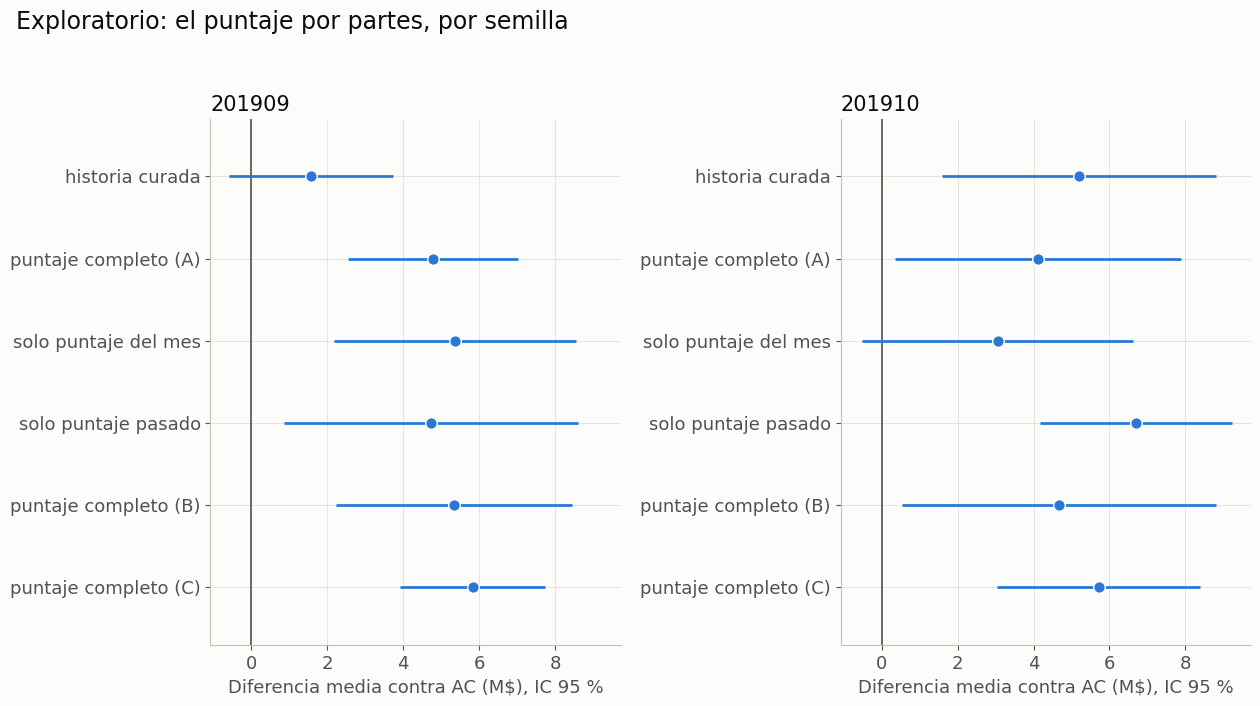

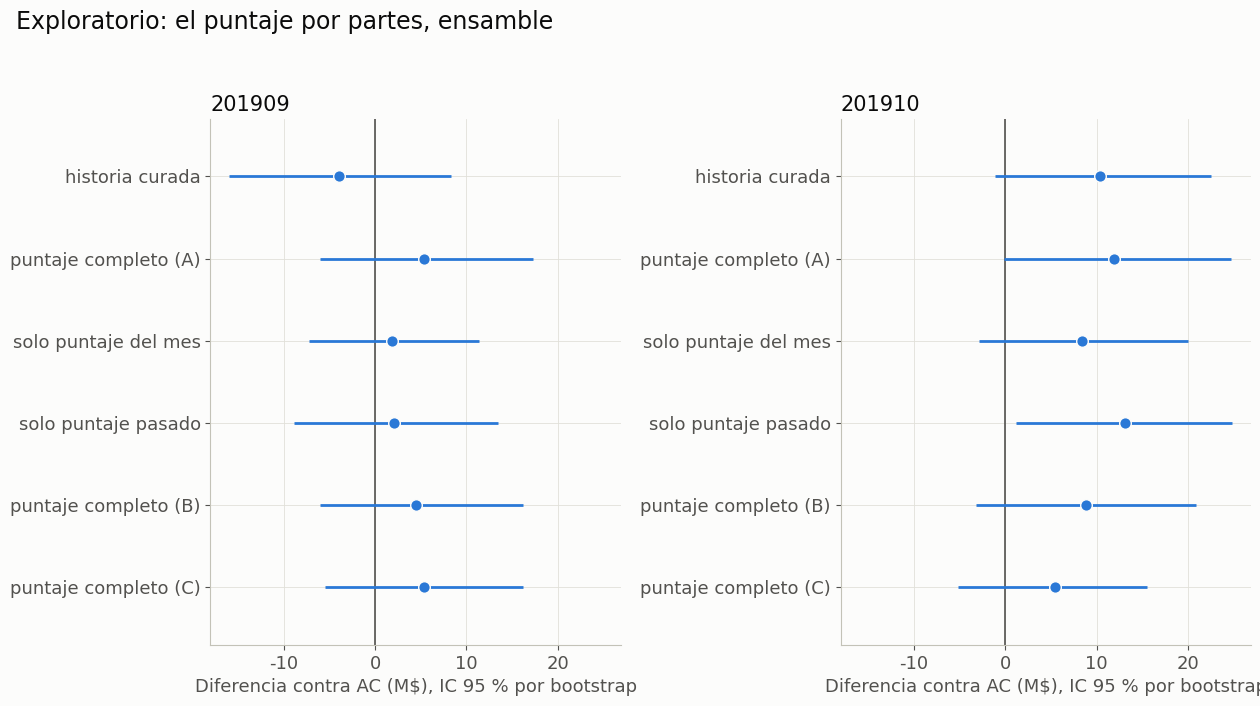

In [8]:
TINTA_2, GRILLA, AZUL = '#52514e', '#e1e0d9', '#2a78d6'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2, 'text.color': '#0b0b0b',
                     'axes.grid': True, 'grid.color': GRILLA, 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 13, 'axes.titlesize': 15})
TAMANO, DPI = (12.8, 7.2), 150


def coma(x, decimales=1):
    return f'{x:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


NOMBRES = {'ACH': 'historia curada', 'ACP': 'puntaje completo (A)', 'ACP0': 'solo puntaje del mes',
           'ACPH': 'solo puntaje pasado', 'ACP_B': 'puntaje completo (B)', 'ACP_C': 'puntaje completo (C)'}
LISTA = CONTRASTES[CONTROL]


def figura(medida, titulo, rotulo, archivo):
    fig, ejes = plt.subplots(1, 2, figsize=TAMANO, sharex=True)
    etiquetas = [NOMBRES[c] for c in LISTA]
    y = np.arange(len(etiquetas))[::-1]
    for ax, m in zip(ejes, MESES_TEST):
        t = comparacion[(comparacion['medida'] == medida) & (comparacion['foto_mes'] == m) & (comparacion['contra'] == CONTROL)].set_index('config').loc[LISTA]
        ax.axvline(0, color=TINTA_2, lw=1.2)
        ax.hlines(y, t['ic95_inf_M'], t['ic95_sup_M'], color=AZUL, lw=2)
        ax.scatter(t['d_M'], y, s=70, color=AZUL, zorder=3, edgecolor='#fcfcfb')
        ax.set_yticks(y, etiquetas)
        ax.set_ylim(-0.7, len(etiquetas) - 0.3)
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: coma(v, 0 if float(v).is_integer() else 1)))
        ax.set_title(str(m), loc='left')
        ax.set_xlabel(rotulo)
    fig.suptitle(titulo, x=0.02, ha='left', fontsize=17)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(FIGURAS / archivo, dpi=DPI)
    plt.show()


figura('semillas', 'Exploratorio: el puntaje por partes, por semilla',
       'Diferencia media contra AC (M$), IC 95 %', '10_1_por_semilla.png')
figura('ensamble', 'Exploratorio: el puntaje por partes, ensamble',
       'Diferencia contra AC (M$), IC 95 % por bootstrap', '10_2_ensamble.png')

## 9. Lecturas fijadas antes de correr

**¿Es historia?**
- **Sí,** si `ACPH` cumple el criterio contra `AC` y su banda por semilla supera a la de `ACP0` en los dos meses.
- **Es apilar modelos,** si `ACP0` cumple el criterio y `ACPH` no.
- **No se puede separar,** si las dos lo cumplen sin que `ACPH` supere a `ACP0`.
- **Depende de la combinación,** si ninguna lo cumple.

**¿Es robusto?**
- **Sí,** si `ACP_B` y `ACP_C` cumplen el criterio contra `AC`.
- **Frágil,** si lo cumple una sola.
- **No,** si no lo cumple ninguna.

El criterio es el del `08`: diferencia positiva en los dos meses en la media por semilla, en la banda por semilla y en la banda del ensamble. **Control:** las salidas anteriores no cambiaron.

In [9]:
assert huella_archivos() == HUELLA_INICIAL, 'Cambiaron las salidas anteriores'   # control 8
print(f'Control de salidas OK · {(time.time() - T_INICIO) / 60:.1f} min en total · memoria máxima {memoria_gb()} GB')
if segundos:
    print('Segundos por modelo:', {c: round(float(np.mean(v)), 1) for c, v in segundos.items()})
print()
print('EXPLORATORIO: no cambia el resultado de la regla pre-registrada.')
print()


def cumple(c, contra=CONTROL):
    t = comparacion[(comparacion['config'] == c) & (comparacion['contra'] == contra)]
    s, e = t[t['medida'] == 'semillas'], t[t['medida'] == 'ensamble']
    return bool((s['d_M'] > 0).all()), bool((s['d_banda_M'] > 0).all()), bool((e['d_banda_M'] > 0).all())


si_no = lambda x: 'sí' if x else 'no'
pasa = {}
for c in ['ACP'] + list(VARIANTES):
    uno, dos, tres = cumple(c)
    pasa[c] = uno and dos and tres
    print(f'{c} ({NOMBRES[c]}) contra AC: media {si_no(uno)} · banda {si_no(dos)} · banda ensamble {si_no(tres)}')

s = comparacion[(comparacion['medida'] == 'semillas') & (comparacion['config'] == 'ACPH') & (comparacion['contra'] == 'ACP0')]
supera = bool((s['d_banda_M'] > 0).all())
if pasa['ACPH'] and supera:
    historia = 'sí, es historia'
elif pasa['ACP0'] and not pasa['ACPH']:
    historia = 'es apilar modelos'
elif pasa['ACP0'] and pasa['ACPH']:
    historia = 'no se puede separar'
elif pasa['ACPH']:
    historia = 'ACPH cumple, pero no supera a ACP0 en la banda'
else:
    historia = 'depende de la combinación'
otras = int(pasa['ACP_B']) + int(pasa['ACP_C'])
print()
print('¿Es historia?', historia)
print('¿Es robusto?', {2: 'sí', 1: 'frágil', 0: 'no'}[otras])
print()
t = comparacion[(comparacion['contra'] == CONTROL) & comparacion['config'].isin(COMPLETAS)]
print('Media de las 3 particiones, contra AC (M):')
print(t.groupby(['medida', 'foto_mes'])[['d_M', 'd_banda_M']].mean().round(2).to_string())

Control de salidas OK · 34.7 min en total · memoria máxima 4.4 GB
Segundos por modelo: {'ACP0': 36.9, 'ACPH': 37.7, 'ACP_B': 38.1, 'ACP_C': 41.7}

EXPLORATORIO: no cambia el resultado de la regla pre-registrada.

ACP (puntaje completo (A)) contra AC: media sí · banda sí · banda ensamble sí
ACP0 (solo puntaje del mes) contra AC: media sí · banda sí · banda ensamble sí
ACPH (solo puntaje pasado) contra AC: media sí · banda sí · banda ensamble sí
ACP_B (puntaje completo (B)) contra AC: media sí · banda sí · banda ensamble no
ACP_C (puntaje completo (C)) contra AC: media sí · banda sí · banda ensamble no

¿Es historia? no se puede separar
¿Es robusto? no

Media de las 3 particiones, contra AC (M):
                    d_M  d_banda_M
medida   foto_mes                 
ensamble 201909    5.07       0.44
         201910    8.74       5.21
semillas 201909    5.32       2.26
         201910    4.84       4.97
